# Funktionen mehrerer Veränderlicher VIII: Extrema mit Nebenbedingungen (Lagrange)

**Begleit-Notebook zum Vorlesungsskript „Angewandte Mathematik – 2. Funktionen mehrerer Veränderlicher“ (Abschnitt 2.8.2)**

Das Notebook folgt der Gliederung des Skripts. Definitionen, Sätze und Beispiele tragen dieselbe Nummer wie im Skript. Zu den Beispielen gibt es

* den Rechenweg aus dem Skript in Formeln,
* eine **Probe mit SymPy** (das Residuum muss 0 sein),
* eine **Grafik** und an einigen Stellen ein **interaktives Element** (Schieberegler),

**Voraussetzungen:** `numpy`, `sympy`, `matplotlib`, `ipywidgets`
**Arbeitsweise:** Zellen der Reihe nach ausführen und die Kontrollausgaben prüfen.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/karkessler/dhbw-mathe3/blob/main/notebooks/funktionen_mehrerer_veraenderlicher/08_extrema_mit_nebenbedingungen.ipynb)

**Inhalt**


1. Beispiel 2.8.2.1: Nutzenmaximierung mit Budget, warum ohne Nebenbedingung nichts herauskommt
2. Definition 2.8.2.2 und Satz 2.8.2.3: Multiplikatorregel von Lagrange
3. Fortsetzung von Beispiel 2.8.2.1: Lösung und geometrische Deutung (interaktiv)
4. Beispiel 2.8.2.4: vier Variablen, eine Nebenbedingung
5. Beispiel 2.8.2.5: zwei Nebenbedingungen
6. Bemerkung 2.8.2.6: Bedeutung des Multiplikators (Schattenpreis)


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown
from matplotlib import cm
plt.style.use('default')
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'savefig.transparent': False,
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'axes.titlecolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'text.color': 'black',
    'axes.grid': True,
    'grid.color': '0.8',
    'legend.facecolor': 'white',
    'legend.edgecolor': '0.7',
})
sp.init_printing()

x, y, z = sp.symbols('x y z', real=True)
ROT, BLAU = '#d71920', '#0b5cad'


def pruefe(name, residuum):
    """Vereinfacht ein Residuum, gibt es aus und bricht ab, falls es nicht 0 ist."""
    r = sp.simplify(residuum)
    if isinstance(r, sp.MatrixBase):
        ok = all(sp.simplify(e) == 0 for e in r)
    else:
        ok = r == 0
    print(f'Probe {name}: Residuum = {r}  ->', 'ok' if ok else 'FEHLER')
    assert ok


def flaeche(f, xbereich, ybereich, n=60, ax=None, titel=None, cmap='YlOrBr_r', alpha=1.0, blick=(30, -60)):
    """Zeichnet z = f(x, y) als Fläche (f als NumPy-Funktion). Gibt die Achse zurück."""
    if ax is None:
        fig = plt.figure(figsize=(7, 5))
        ax = fig.add_subplot(projection='3d')
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    ax.plot_surface(X, Y, Z, cmap=cmap, alpha=alpha, linewidth=0.2, edgecolor=(0.3, 0.15, 0, 0.3),
                    rstride=max(1, n // 30), cstride=max(1, n // 30))
    ax.set(xlabel='x', ylabel='y', zlabel='z')
    ax.view_init(*blick)
    if titel:
        ax.set_title(titel)
    return ax


def hoehenlinien(f, xbereich, ybereich, n=300, ax=None, niveaus=12, titel=None, gefuellt=True):
    """Zeichnet die Höhenlinien f(x, y) = c (optional eingefärbt). Gibt die Achse zurück."""
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xbereich, n), np.linspace(*ybereich, n))
    Z = f(X, Y)
    if gefuellt:
        cf = ax.contourf(X, Y, Z, levels=niveaus, cmap='YlOrBr_r', extend='both')
        plt.colorbar(cf, ax=ax, shrink=0.85)
    cs = ax.contour(X, Y, Z, levels=niveaus, colors='0.25', linewidths=0.7)
    ax.clabel(cs, fontsize=7, fmt='%.2g')
    ax.set(xlabel='x', ylabel='y', aspect='equal')
    if titel:
        ax.set_title(titel)
    return ax

lam, lam1, lam2 = sp.symbols('lambda lambda_1 lambda_2', real=True)


def stationaer(L, variablen):
    """Stationäre Punkte der Lagrangefunktion: alle partiellen Ableitungen gleich 0."""
    return sp.solve([sp.diff(L, v) for v in variablen], variablen, dict=True)

## 1. Beispiel 2.8.2.1: Nutzenmaximierung

Der Nutzen beim Kauf von $x$ Einheiten Salami und $y$ Einheiten Schinken sei $U(x,y) = 2xy$ ($x, y\ge 0$). Bei Preisen $p_x = 3$, $p_y = 2$ und einem Budget von 60 lautet die Restriktion
$$g(x,y) = 60 - 3x - 2y = 0.$$
Ohne Nebenbedingung liefert $U_x = 2y = 0$, $U_y = 2x = 0$ nur den Punkt $(0,0)$: Dort wird nichts eingekauft, der Nutzen ist mit 0 auf $x, y\ge 0$ minimal (auf ganz $\mathbb{R}^2$ ist $(0,0)$ ein Sattelpunkt von $U$). Ein freies Maximum gibt es nicht.

In [2]:
U = 2*x*y
g = 60 - 3*x - 2*y
frei = sp.solve([sp.diff(U, x), sp.diff(U, y)], [x, y], dict=True)
print('stationäre Punkte ohne Nebenbedingung:', frei)
print('Hesse-Matrix dort:', sp.hessian(U, (x, y)).tolist(), ' Determinante', sp.hessian(U, (x, y)).det(), '< 0: Sattelpunkt')

stationäre Punkte ohne Nebenbedingung: [{x: 0, y: 0}]
Hesse-Matrix dort: [[0, 2], [2, 0]]  Determinante -4 < 0: Sattelpunkt


## 2. Definition 2.8.2.2 und Satz 2.8.2.3: Multiplikatorregel von Lagrange

Gesucht ist das Maximum (Minimum) von $Z = f(x_1,\dots,x_n)$ unter $m < n$ Nebenbedingungen $g_1 = 0,\ \dots,\ g_m = 0$. Sind die Gradienten der $g_i$ im gesuchten Punkt linear unabhängig, so liegt jedes relative Extremum unter den stationären Stellen der **Lagrangefunktion**
$$L(x_1,\dots,x_n,\lambda_1,\dots,\lambda_m) = f(x_1,\dots,x_n) + \sum_{i=1}^m \lambda_i\,g_i(x_1,\dots,x_n).$$
Das sind $n + m$ Gleichungen: $\dfrac{\partial L}{\partial x_k} = 0$ für $k = 1,\dots,n$ und $\dfrac{\partial L}{\partial \lambda_i} = g_i = 0$ für $i = 1,\dots,m$. Die $\lambda_i$ heißen **Lagrange'sche Multiplikatoren**.

**Geometrisch** ($n = 2$, $m = 1$): Im gesuchten Punkt berührt die Kurve $g = 0$ eine Höhenlinie von $f$. Die Gradienten sind dort parallel: $\operatorname{grad} f + \lambda\,\operatorname{grad} g = 0$.

## 3. Fortsetzung von Beispiel 2.8.2.1

$L(x,y,\lambda) = 2xy + \lambda(60 - 3x - 2y)$ liefert
$$L_x = 2y - 3\lambda = 0,\qquad L_y = 2x - 2\lambda = 0,\qquad L_\lambda = 60 - 3x - 2y = 0.$$
Also $x = \lambda$, $y = \tfrac{3}{2}\lambda$, eingesetzt $60 - 6\lambda = 0$: $\lambda = 10$, $x = 10$, $y = 15$ und $U(10,15) = 300$. Auf der Budgetgeraden ist $U = 2x\,(30 - \tfrac{3}{2}x) = 60x - 3x^2$ eine nach unten geöffnete Parabel, es ist also ein Maximum.

In [3]:
L = U + lam*g
loes = stationaer(L, [x, y, lam])
print(loes)
pruefe('x = 10', loes[0][x] - 10); pruefe('y = 15', loes[0][y] - 15); pruefe('lambda = 10', loes[0][lam] - 10)
pruefe('U(10,15) = 300', U.subs(loes[0]) - 300)
auf_gerade = sp.expand(U.subs(y, sp.solve(g, y)[0]))
pruefe('U auf der Budgetgeraden = 60x - 3x²', auf_gerade - (60*x - 3*x**2))
gradU = sp.Matrix([sp.diff(U, v) for v in (x, y)]).subs(loes[0])
gradg = sp.Matrix([sp.diff(g, v) for v in (x, y)]).subs(loes[0])
print('grad U =', list(gradU), ',  grad g =', list(gradg))
pruefe('grad U + lambda grad g = 0', gradU + 10*gradg)

[{lambda: 10, x: 10, y: 15}]
Probe x = 10: Residuum = 0  -> ok
Probe y = 15: Residuum = 0  -> ok
Probe lambda = 10: Residuum = 0  -> ok
Probe U(10,15) = 300: Residuum = 0  -> ok
Probe U auf der Budgetgeraden = 60x - 3x²: Residuum = 0  -> ok
grad U = [30, 20] ,  grad g = [-3, -2]
Probe grad U + lambda grad g = 0: Residuum = Matrix([[0], [0]])  -> ok


**Interaktiv:** Ein Punkt läuft auf der Budgetgeraden $3x + 2y = 60$. Gezeigt sind die Höhenlinie von $U$ durch diesen Punkt, $\operatorname{grad} U$ (rot) und $\operatorname{grad} g$ (blau). Nur bei $x = 10$ sind beide Gradienten parallel; dort berührt die Gerade die Höhenlinie $U = 300$.

FloatSlider(value=5.0, continuous_update=False, description='x', max=19.5, min=0.5, step=0.5)

Output()

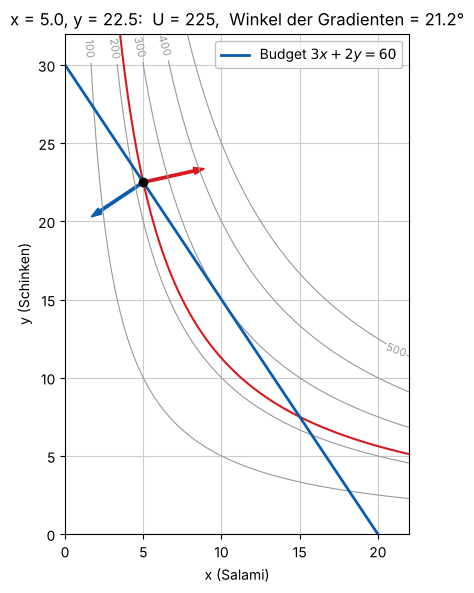

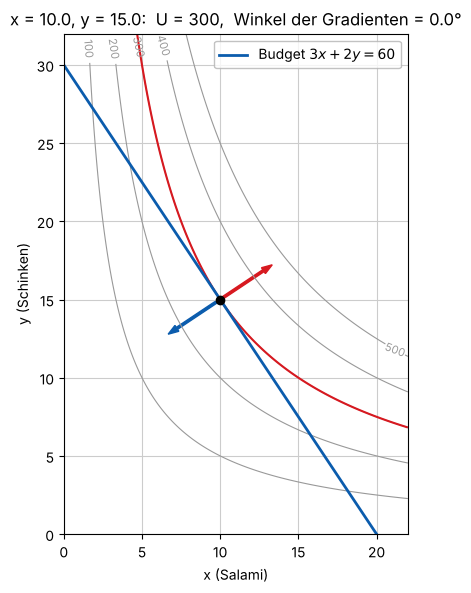

In [4]:
Un = sp.lambdify((x, y), U, 'numpy')
X, Y = np.meshgrid(np.linspace(0, 22, 300), np.linspace(0, 32, 300))


def zeige_budget(x0=5.0):
    y0 = 30 - 1.5*x0
    gu, gg = np.array([2*y0, 2*x0]), np.array([-3.0, -2.0])
    winkel = np.degrees(np.arccos(abs(gu @ gg)/(np.linalg.norm(gu)*np.linalg.norm(gg)) if np.linalg.norm(gu) > 0 else 1))
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    cs = ax.contour(X, Y, Un(X, Y), levels=[100, 200, 300, 400, 500], colors='0.6', linewidths=0.8)
    ax.clabel(cs, fontsize=8)
    ax.contour(X, Y, Un(X, Y), levels=[max(Un(x0, y0), 1e-6)], colors=[ROT], linewidths=1.5)
    xs = np.linspace(0, 20, 2)
    ax.plot(xs, 30 - 1.5*xs, color=BLAU, lw=2, label='Budget $3x + 2y = 60$')
    ax.plot(x0, y0, 'ko')
    for v, farbe in [(gu, ROT), (gg, BLAU)]:
        e = v/np.linalg.norm(v)*4 if np.linalg.norm(v) > 0 else v
        ax.arrow(x0, y0, e[0], e[1], width=0.15, color=farbe, length_includes_head=True)
    ax.set(xlim=(0, 22), ylim=(0, 32), aspect='equal', xlabel='x (Salami)', ylabel='y (Schinken)',
           title=f'x = {x0:.1f}, y = {y0:.1f}:  U = {Un(x0, y0):.0f},  Winkel der Gradienten = {winkel:.1f}°')
    ax.legend(loc='upper right')
    plt.show()


x_r = widgets.FloatSlider(value=5.0, min=0.5, max=19.5, step=0.5, description='x', continuous_update=False)
display(x_r, widgets.interactive_output(zeige_budget, {'x0': x_r}))

# Statische Vorschau für GitHub: ein beliebiger Punkt und das Optimum.
zeige_budget(5.0)
zeige_budget(10.0)

## 4. Beispiel 2.8.2.4

Gesucht sind die relativen Extrema von $f(x_1,x_2,x_3,x_4) = x_1^4 + x_2^4 + x_3^4 + x_4^4$ unter $x_1 + x_2 + x_3 + x_4 = 8$.

Mit $L = x_1^4 + x_2^4 + x_3^4 + x_4^4 + \lambda(8 - x_1 - x_2 - x_3 - x_4)$ folgt $4x_i^3 = \lambda$ für alle $i$, also $x_1 = x_2 = x_3 = x_4$ und mit der Restriktion $x_i = 2$, $\lambda = 32$. Der einzige Kandidat ist $(2,2,2,2)$ mit $f = 64$. Es ist ein Minimum, denn auf der Hyperebene wächst $f$ für betragsmäßig große $x_i$ über alle Grenzen.

In [5]:
xs4 = sp.symbols('x1:5', real=True)
f2824 = sum(v**4 for v in xs4)
L4 = f2824 + lam*(8 - sum(xs4))
bed = [sp.diff(L4, v) for v in list(xs4) + [lam]]
display(bed)
# x -> x³ ist auf R injektiv: aus 4x_i³ = lambda folgt x_1 = x_2 = x_3 = x_4 =: t
t4 = sp.symbols('t', real=True)
loes4 = sp.solve([4*t4**3 - lam, 8 - 4*t4], [t4, lam], dict=True)
print('reelle Lösung:', loes4)
punkt = {v: loes4[0][t4] for v in xs4}
pruefe('alle Bedingungen erfüllt', sp.Matrix([e.subs(punkt).subs(lam, loes4[0][lam]) for e in bed]))
pruefe('x_i = 2', loes4[0][t4] - 2)
pruefe('lambda = 32', loes4[0][lam] - 32)
pruefe('f(2,2,2,2) = 64', f2824.subs(punkt) - 64)

# Stichprobe: f ist auf der Hyperebene nirgends kleiner als 64
rng = np.random.default_rng(0)
P = rng.normal(0, 3, size=(200_000, 3))
P = np.column_stack([P, 8 - P.sum(axis=1)])
print('kleinster Wert in 200 000 Zufallspunkten der Hyperebene:', (P**4).sum(axis=1).min())

reelle Lösung: [{lambda: 32, t: 2}]
Probe alle Bedingungen erfüllt: Residuum = Matrix([[0], [0], [0], [0], [0]])  -> ok
Probe x_i = 2: Residuum = 0  -> ok
Probe lambda = 32: Residuum = 0  -> ok
Probe f(2,2,2,2) = 64: Residuum = 0  -> ok
kleinster Wert in 200 000 Zufallspunkten der Hyperebene: 64.39439953600302


## 5. Beispiel 2.8.2.5: zwei Nebenbedingungen

Gesucht sind die Stellen, an denen $f(x,y,z) = x^2 + 3y^2 + 2z^2$ unter $x + 3y = 30$ und $y + 2z = 20$ relative Extrema haben kann.
$$L = x^2 + 3y^2 + 2z^2 + \lambda_1(x + 3y - 30) + \lambda_2(y + 2z - 20).$$
Die fünf Bedingungen $L_x = 2x + \lambda_1 = 0$, $L_y = 6y + 3\lambda_1 + \lambda_2 = 0$, $L_z = 4z + 2\lambda_2 = 0$, $L_{\lambda_1} = x + 3y - 30 = 0$, $L_{\lambda_2} = y + 2z - 20 = 0$ bilden ein **lineares** Gleichungssystem mit der eindeutigen Lösung
$$(x,y,z,\lambda_1,\lambda_2) = (6,\ 8,\ 6,\ -12,\ -12),\qquad f(6,8,6) = 36 + 192 + 72 = 300.$$

⎡2  0  0  1  0⎤ ⎡x ⎤   ⎡0 ⎤
⎢             ⎥ ⎢  ⎥   ⎢  ⎥
⎢0  6  0  3  1⎥ ⎢y ⎥   ⎢0 ⎥
⎢             ⎥ ⎢  ⎥   ⎢  ⎥
⎢0  0  4  0  2⎥⋅⎢z ⎥ = ⎢0 ⎥
⎢             ⎥ ⎢  ⎥   ⎢  ⎥
⎢1  3  0  0  0⎥ ⎢λ₁⎥   ⎢30⎥
⎢             ⎥ ⎢  ⎥   ⎢  ⎥
⎣0  1  2  0  0⎦ ⎣λ₂⎦   ⎣20⎦

Lösung (x, y, z, λ1, λ2) = [6, 8, 6, -12, -12]
Probe Skript-Ergebnis: Residuum = Matrix([[0], [0], [0], [0], [0]])  -> ok
Probe f(6,8,6) = 300: Residuum = 0  -> ok


Minimum auf der Schnittgeraden bei t = [8] (t = y = 8): ein Minimum, da f(t) nach oben geöffnet ist


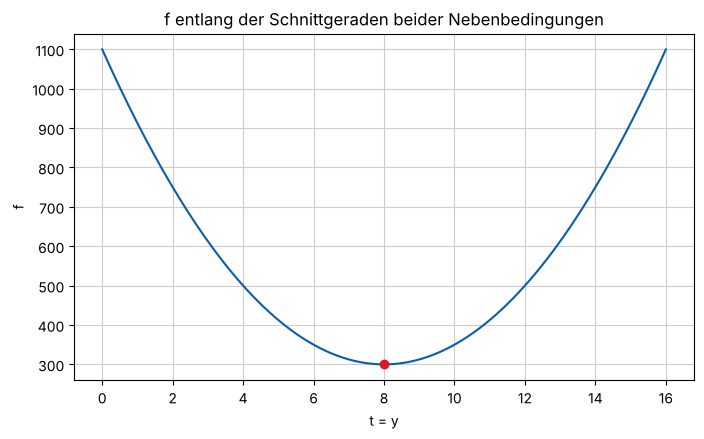

In [6]:
z_ = z
f2825 = x**2 + 3*y**2 + 2*z_**2
L5 = f2825 + lam1*(x + 3*y - 30) + lam2*(y + 2*z_ - 20)
var5 = [x, y, z_, lam1, lam2]
A, b = sp.linear_eq_to_matrix([sp.diff(L5, v) for v in var5], var5)
display(sp.Eq(sp.MatMul(A, sp.Matrix(var5), evaluate=False), b, evaluate=False))
loes5 = A.LUsolve(b)
print('Lösung (x, y, z, λ1, λ2) =', list(loes5))
pruefe('Skript-Ergebnis', loes5 - sp.Matrix([6, 8, 6, -12, -12]))
pruefe('f(6,8,6) = 300', f2825.subs({x: 6, y: 8, z_: 6}) - 300)

# Die beiden Ebenen schneiden sich in einer Geraden: x = 30 - 3t, y = t, z = 10 - t/2
t_ = sp.symbols('t', real=True)
auf_gerade = sp.expand(f2825.subs({x: 30 - 3*t_, y: t_, z_: 10 - t_/2}))
display(sp.Eq(sp.Symbol('f(t)'), auf_gerade))
print('Minimum auf der Schnittgeraden bei t =', sp.solve(sp.diff(auf_gerade, t_), t_), '(t = y = 8): ein Minimum, da f(t) nach oben geöffnet ist')
ts = np.linspace(0, 16, 200)
plt.plot(ts, sp.lambdify(t_, auf_gerade)(ts), color=BLAU)
plt.plot(8, 300, 'o', color=ROT)
plt.xlabel('t = y'); plt.ylabel('f'); plt.title('f entlang der Schnittgeraden beider Nebenbedingungen')
plt.show()

## 6. Bemerkung 2.8.2.6: Bedeutung des Multiplikators

In Beispiel 2.8.2.1 ergab sich $\lambda = 10$. Ersetzt man das Budget 60 durch $B$, so liefert dieselbe Rechnung $x = \lambda = \frac{B}{6}$, $y = \frac{B}{4}$ und $U^*(B) = \frac{B^2}{12}$. Also
$$\frac{dU^*}{dB} = \frac{B}{6} = \lambda.$$
Der Multiplikator gibt an, um wie viel der optimale Wert steigt, wenn die Restriktion um eine Einheit gelockert wird (**Schattenpreis**): $U^*(61)\approx 310{,}1$, also etwa $10$ mehr als $U^*(60) = 300$.

In [7]:
B = sp.symbols('B', positive=True)
loesB = stationaer(U + lam*(B - 3*x - 2*y), [x, y, lam])[0]
U_opt = sp.simplify(U.subs(loesB))
display(loesB, sp.Eq(sp.Symbol('U^*(B)'), U_opt))
pruefe('dU*/dB = lambda', sp.diff(U_opt, B) - loesB[lam])
print('U*(60) =', U_opt.subs(B, 60), ',  U*(61) =', float(U_opt.subs(B, 61)), ',  Differenz =', float(U_opt.subs(B, 61) - U_opt.subs(B, 60)))

Probe dU*/dB = lambda: Residuum = 0  -> ok
U*(60) = 300 ,  U*(61) = 310.0833333333333 ,  Differenz = 10.083333333333334
